# Codveda ML Internship - Level 2 (Intermediate)
- Task 1: Logistic Regression for Binary Classification
- Task 2: Decision Trees for Classification
- Task 3: K-Means Clustering

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_iris, load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_curve,
                             roc_auc_score, classification_report, silhouette_score)

---
# Task 1: Logistic Regression for Binary Classification
Dataset: Breast Cancer Wisconsin (built in). Target: 1 = benign, 0 = malignant.

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Missing values:", X.isna().sum().sum())   # preprocessing check: none missing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Missing values: 0


In [3]:
log_reg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
pred = log_reg.predict(X_test_s)
proba = log_reg.predict_proba(X_test_s)[:, 1]
print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("ROC AUC  :", round(roc_auc_score(y_test, proba), 3))

Accuracy : 0.982
Precision: 0.986
Recall   : 0.986
ROC AUC  : 0.995


### Coefficients and odds ratios
Odds ratio = exp(coefficient). For a standardized feature, it is the multiplicative change in the odds of the outcome (benign) for a 1-standard-deviation increase in that feature. Above 1 raises the odds, below 1 lowers them.

In [4]:
coef = pd.DataFrame({"coefficient": log_reg.coef_[0], "odds_ratio": np.exp(log_reg.coef_[0])}, index=X.columns)
coef.reindex(coef.coefficient.abs().sort_values(ascending=False).index).head(10).round(3)

,coefficient,odds_ratio
worst texture,-1.255,0.285
radius error,-1.083,0.339
worst concave points,-0.954,0.385
worst area,-0.948,0.388
worst radius,-0.948,0.388
worst symmetry,-0.939,0.391
area error,-0.929,0.395
worst concavity,-0.823,0.439
worst perimeter,-0.763,0.466
worst smoothness,-0.747,0.474


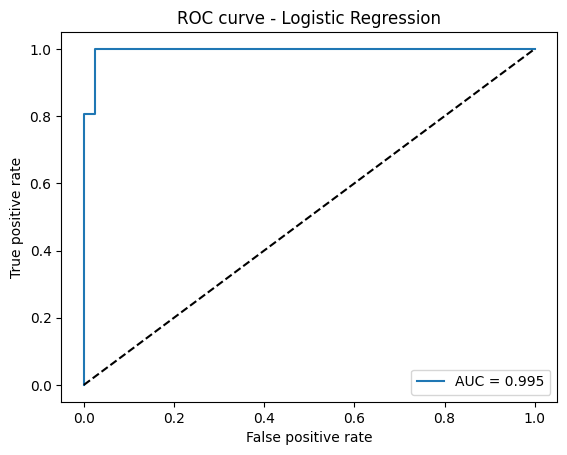

In [5]:
fpr, tpr, _ = roc_curve(y_test, proba)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve - Logistic Regression"); plt.legend()
plt.savefig("logreg_roc.png", dpi=150); plt.show()

---
# Task 2: Decision Trees for Classification
Dataset: Iris.

In [6]:
iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, random_state=42, stratify=yi)

full_tree = DecisionTreeClassifier(random_state=42).fit(Xi_train, yi_train)
print("Unpruned -> train acc:", round(full_tree.score(Xi_train, yi_train), 3), "| test acc:", round(full_tree.score(Xi_test, yi_test), 3))
print("Depth:", full_tree.get_depth(), "| leaves:", full_tree.get_n_leaves())

Unpruned -> train acc: 1.0 | test acc: 0.933
Depth: 5 | leaves: 8


### Pruning
We search over pruning settings with 5-fold cross-validation on the training set: `ccp_alpha` (cost-complexity pruning), `max_depth` and `min_samples_leaf` (pre-pruning).

In [7]:
from sklearn.model_selection import GridSearchCV
alphas = np.unique(np.round(full_tree.cost_complexity_pruning_path(Xi_train, yi_train).ccp_alphas, 4))
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    {"ccp_alpha": alphas, "max_depth": [2, 3, 4, 5], "min_samples_leaf": [1, 2, 5]}, cv=5)
grid.fit(Xi_train, yi_train)
print("Best pruning settings:", grid.best_params_, "| CV accuracy:", round(grid.best_score_, 3))
pruned = grid.best_estimator_
print("Pruned   -> train acc:", round(pruned.score(Xi_train, yi_train), 3), "| test acc:", round(pruned.score(Xi_test, yi_test), 3))
print("Depth:", pruned.get_depth(), "| leaves:", pruned.get_n_leaves())

Best pruning settings: {'ccp_alpha': np.float64(0.0), 'max_depth': 3, 'min_samples_leaf': 1} | CV accuracy: 0.952
Pruned   -> train acc: 0.981 | test acc: 0.978
Depth: 3 | leaves: 5


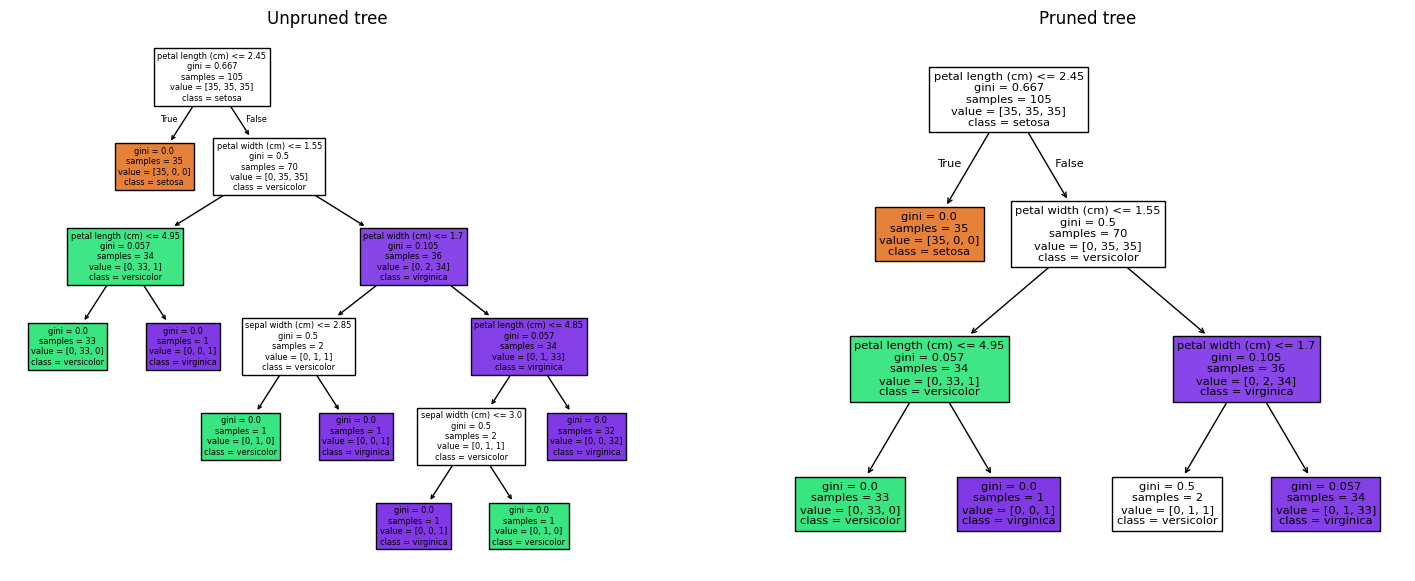

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_tree(full_tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, ax=axes[0]); axes[0].set_title("Unpruned tree")
plot_tree(pruned, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, ax=axes[1]); axes[1].set_title("Pruned tree")
plt.savefig("decision_trees.png", dpi=150); plt.show()

In [9]:
p = pruned.predict(Xi_test)
print("Accuracy:", round(accuracy_score(yi_test, p), 3), "| F1 (macro):", round(f1_score(yi_test, p, average="macro"), 3))
print(classification_report(yi_test, p, target_names=iris.target_names))

Accuracy: 0.978 | F1 (macro): 0.978
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



---
# Task 3: K-Means Clustering


In [10]:
wine = load_wine(as_frame=True)
Xw = wine.data
Xw_s = StandardScaler().fit_transform(Xw)   # scaling is essential for K-Means

### Elbow method (and silhouette score as a second opinion)

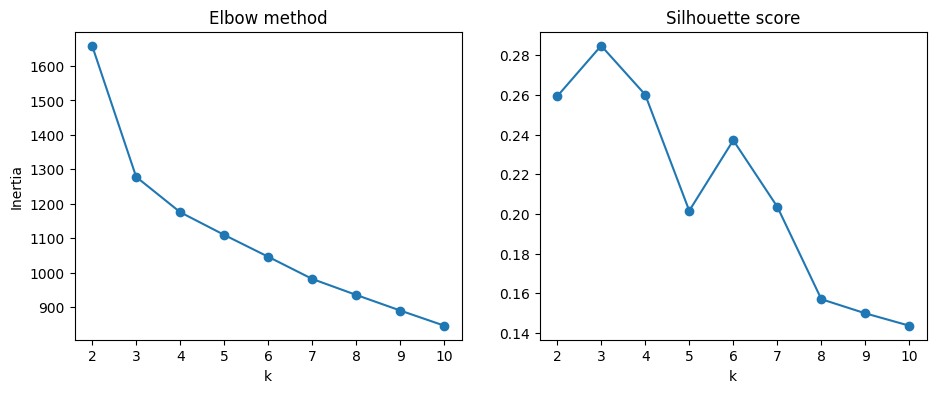

In [11]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xw_s)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xw_s, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.savefig("kmeans_elbow.png", dpi=150); plt.show()

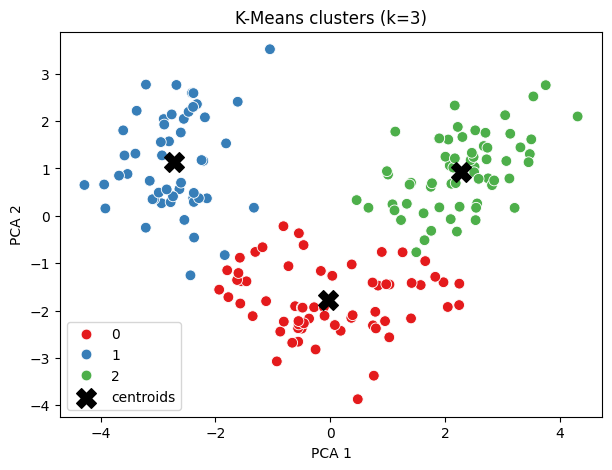

Silhouette: 0.285


In [12]:
k_opt = 3   # the elbow is at k=3 (confirm on your plot)
km = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(Xw_s)
Xw = Xw.assign(cluster=km.labels_)
pcs = PCA(n_components=2).fit_transform(Xw_s)   # 2D projection for plotting
plt.figure(figsize=(7, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=km.labels_, palette="Set1", s=60)
plt.scatter(*PCA(n_components=2).fit(Xw_s).transform(km.cluster_centers_).T, c="black", marker="X", s=200, label="centroids")
plt.xlabel("PCA 1"); plt.ylabel("PCA 2"); plt.title(f"K-Means clusters (k={k_opt})"); plt.legend()
plt.savefig("kmeans_clusters.png", dpi=150); plt.show()
print("Silhouette:", round(silhouette_score(Xw_s, km.labels_), 3))

### Interpret the clusters: average feature values per cluster

In [13]:
profile = Xw.groupby("cluster").mean().round(2)
profile.T

cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45
